# ConvertIQ — session conversion analysis

Reproducible analysis of the UCI Online Shoppers Purchasing Intention data. Run `make download eda train` before executing. No synthetic observations or invented results are used here. Aggregate session attributes cannot establish early-session performance or causality.

In [1]:
from pathlib import Path
import sys
import json

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.config import RAW_FILE, REPORTS
from src.data.schema import validate_frame, quality_report
from src.data.analytics import analytics, statistical_tests
from src.models.inference import get_predictor

data = validate_frame(pd.read_csv(RAW_FILE), target=True, raw=True)
display(data.head())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Quality and descriptive statistics
Raw records are retained for descriptive KPIs. Identical predictor rows are deduplicated only for model splitting. IQR flags describe unusually large values; they do not establish errors.

In [2]:
display(quality_report(data))
display(data.describe(include="all"))

{'rows': 12330,
 'missing_by_column': {'Administrative': 0,
  'Administrative_Duration': 0,
  'Informational': 0,
  'Informational_Duration': 0,
  'ProductRelated': 0,
  'ProductRelated_Duration': 0,
  'BounceRates': 0,
  'ExitRates': 0,
  'PageValues': 0,
  'SpecialDay': 0,
  'Month': 0,
  'OperatingSystems': 0,
  'Browser': 0,
  'Region': 0,
  'TrafficType': 0,
  'VisitorType': 0,
  'Weekend': 0,
  'Revenue': 0},
 'duplicate_rows': 125,
 'iqr_outliers': {'Administrative': 404,
  'Informational': 2631,
  'ProductRelated': 987,
  'Administrative_Duration': 1172,
  'Informational_Duration': 2405,
  'ProductRelated_Duration': 961,
  'BounceRates': 1551,
  'ExitRates': 1099,
  'SpecialDay': 1251},
 'dtypes': {'Administrative': 'int64',
  'Administrative_Duration': 'float64',
  'Informational': 'int64',
  'Informational_Duration': 'float64',
  'ProductRelated': 'int64',
  'ProductRelated_Duration': 'float64',
  'BounceRates': 'float64',
  'ExitRates': 'float64',
  'PageValues': 'float64',


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


## Business KPIs with SQL
The analytics module registers the dataframe with DuckDB and uses SQL GROUP BY, COUNT, SUM and AVG. Segment rates include 95% Wilson intervals; traffic identifiers are anonymous codes.

In [3]:
analysis = analytics(data)
display(analysis["kpis"])
for name, table in analysis["groups"].items():
    print(name)
    display(table)

{'sessions': 12330.0,
 'conversions': 1908.0,
 'conversion_rate': 0.15474452554744525,
 'non_conversion_rate': 0.8452554744525548,
 'average_duration': 1310.037228435889,
 'average_bounce_rate': 0.02219138047072152,
 'average_exit_rate': 0.04307279776650371,
 'conversion_ci': (0.14846839560921418, 0.16123572771923841),
 'Returning_Visitor_conversion_rate': 0.1393232868922377,
 'New_Visitor_conversion_rate': 0.24911452184179456}

Month


,segment,sessions,conversions,conversion_rate,ci_low,ci_high
0,May,3364,365.0,0.108502,0.098435,0.119462
1,Nov,2998,760.0,0.253502,0.238253,0.269383
2,Mar,1907,192.0,0.100682,0.087969,0.115000
3,Dec,1727,216.0,0.125072,0.110298,0.141511
4,Oct,549,115.0,0.209472,0.177509,0.245472
5,Sep,448,86.0,0.191964,0.158174,0.230993
6,Aug,433,76.0,0.175520,0.142586,0.214161
7,Jul,432,66.0,0.152778,0.121923,0.189754
8,June,288,29.0,0.100694,0.071027,0.140874
9,Feb,184,3.0,0.016304,0.005560,0.046833


TrafficType


,segment,sessions,conversions,conversion_rate,ci_low,ci_high
0,2,3913,847.0,0.216458,2.038355e-01,0.229637
1,1,2451,262.0,0.106895,9.527194e-02,0.119749
2,3,2052,180.0,0.087719,7.623696e-02,0.100742
3,4,1069,165.0,0.154350,1.339331e-01,0.177242
4,13,738,43.0,0.058266,4.354196e-02,0.077564
5,10,450,90.0,0.200000,1.656505e-01,0.239428
6,6,444,53.0,0.119369,9.242870e-02,0.152840
7,8,343,95.0,0.276968,2.322775e-01,0.326599
8,5,260,56.0,0.215385,1.697515e-01,0.269306
9,11,247,47.0,0.190283,1.462195e-01,0.243834


VisitorType


,segment,sessions,conversions,conversion_rate,ci_low,ci_high
0,Returning_Visitor,10551,1470.0,0.139323,0.132847,0.146062
1,New_Visitor,1694,422.0,0.249115,0.229102,0.270263
2,Other,85,16.0,0.188235,0.119320,0.284112


Weekend


,segment,sessions,conversions,conversion_rate,ci_low,ci_high
0,False,9462,1409.0,0.148911,0.141881,0.156227
1,True,2868,499.0,0.173989,0.160553,0.188297


SpecialDay


,segment,sessions,conversions,conversion_rate,ci_low,ci_high
0,0.0,11079,1831.0,0.165268,0.158468,0.172300
1,0.6,351,29.0,0.082621,0.058140,0.116140
2,0.8,325,11.0,0.033846,0.019002,0.059582
3,0.4,243,13.0,0.053498,0.031527,0.089366
4,0.2,178,14.0,0.078652,0.047426,0.127680
5,1.0,154,10.0,0.064935,0.035650,0.115397


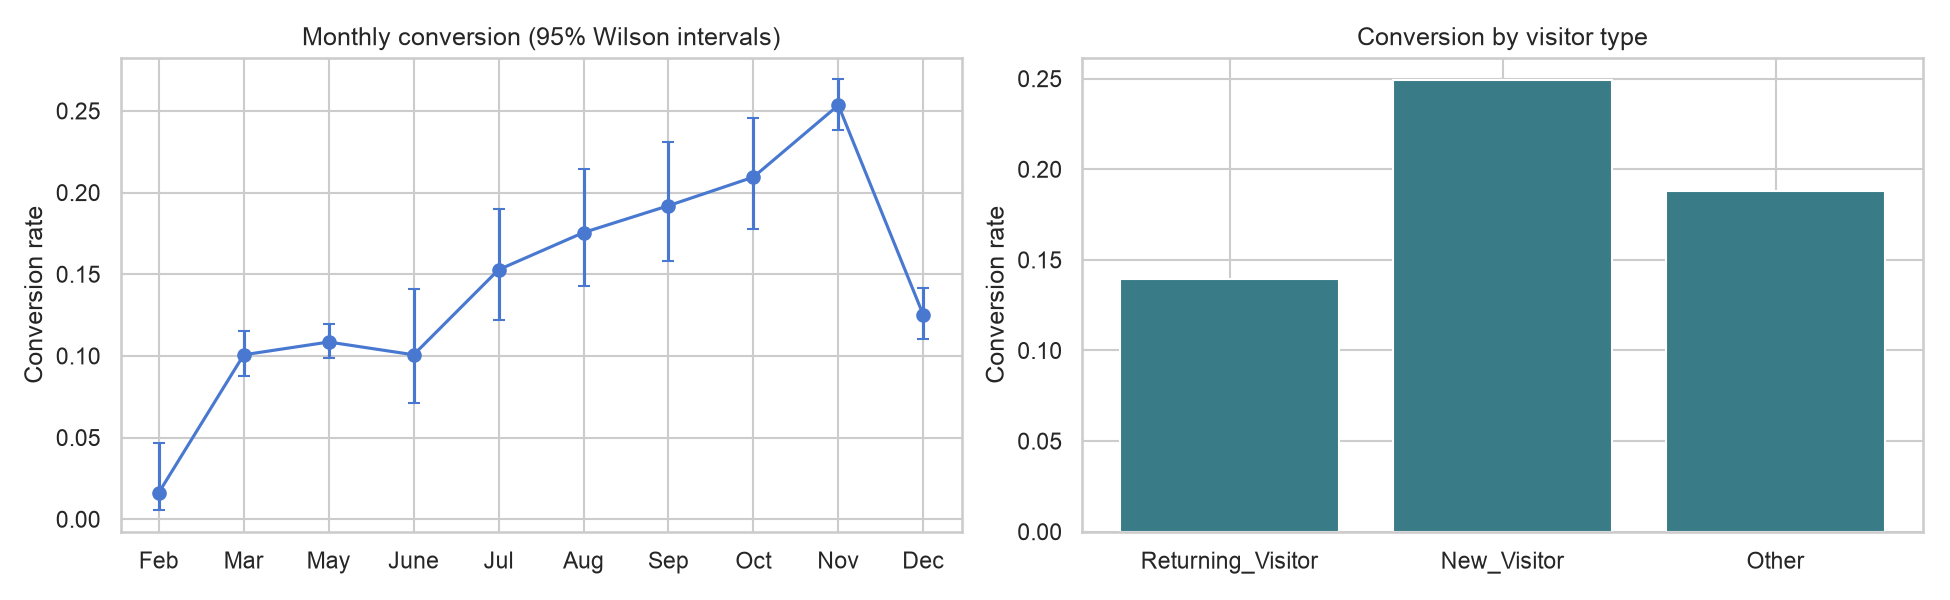

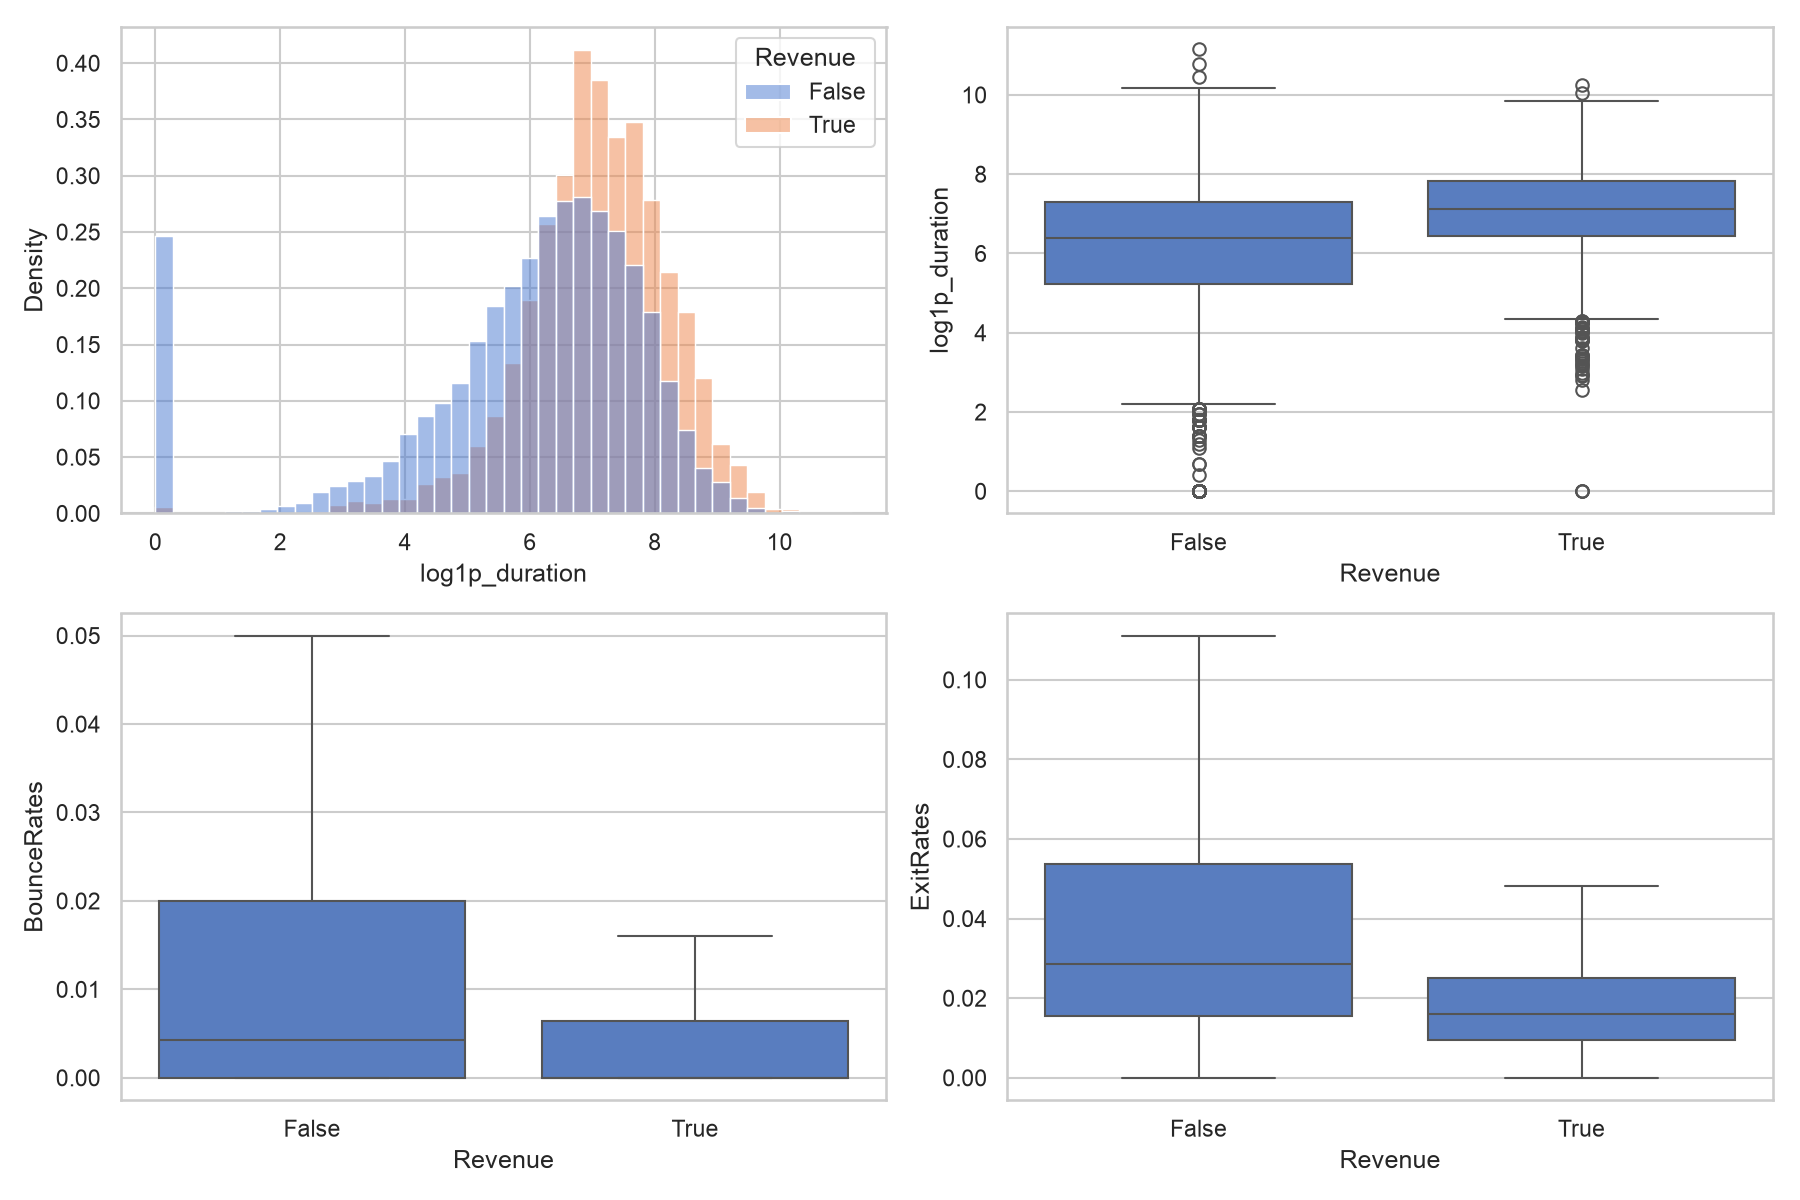

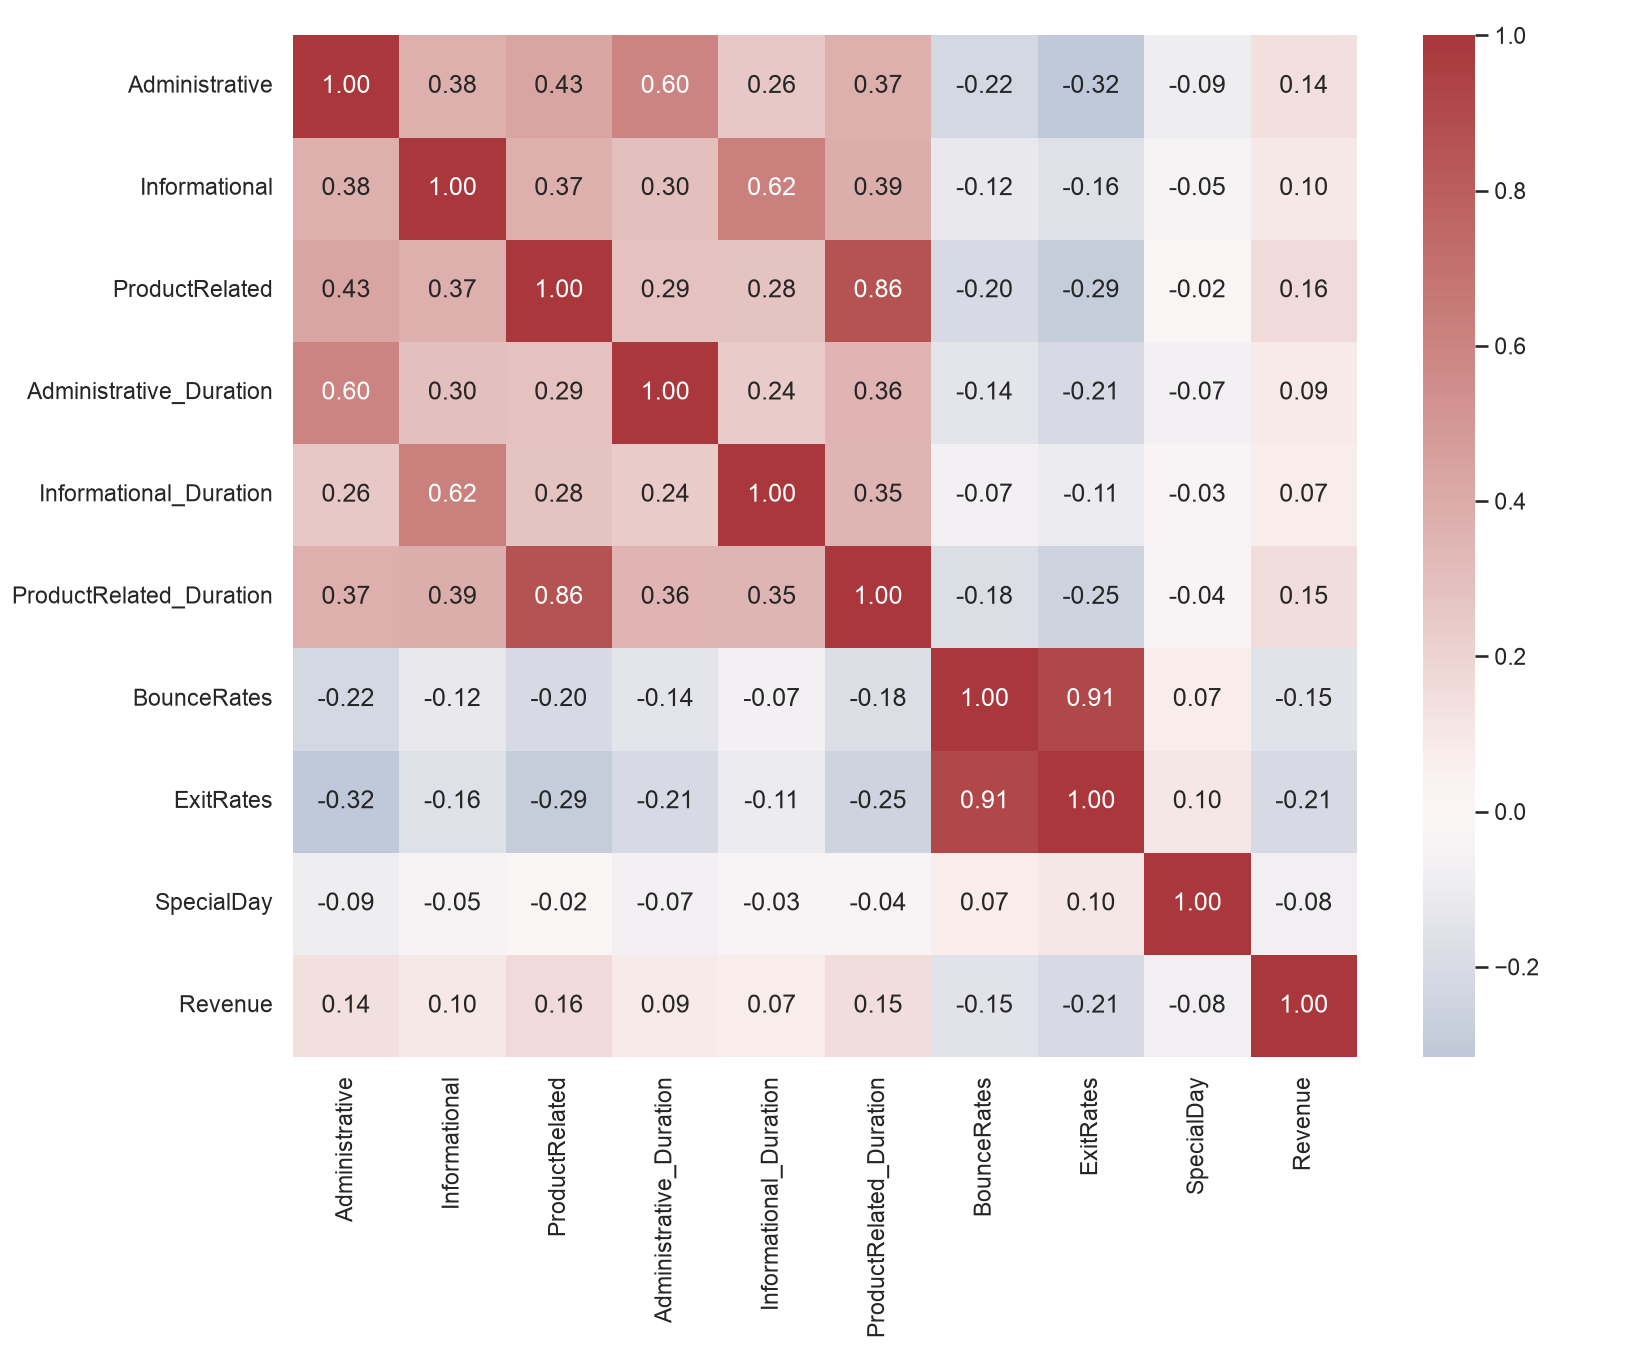

In [4]:
for name in ["conversion_segments.png", "engagement.png", "correlation.png"]:
    display(Image(filename=str(REPORTS / "eda" / name)))

## Statistical evidence
Chi-square tests assess categorical association. Mann–Whitney tests compare numeric distributions; they are not necessarily tests of median differences. Effect sizes and Bonferroni-adjusted p-values are reported. Sparse expected cells weaken chi-square approximations. These are exploratory analyses of the full dataset, not a source of adaptive test-set model tuning.

In [5]:
display(statistical_tests(data))
display(json.loads((REPORTS / "eda/findings.json").read_text()))

,feature,test,statistic,p_value,effect_size,effect_type,sparse_expected_cells,p_bonferroni
0,VisitorType,chi_square,1.352519e+02,4.269904e-30,0.104735,Cramers V,0,5.977866e-29
1,Month,chi_square,3.849348e+02,2.238786e-77,0.176690,Cramers V,0,3.134300e-76
2,TrafficType,chi_square,3.731456e+02,1.652735e-67,0.173963,Cramers V,9,2.313829e-66
3,Weekend,chi_square,1.039098e+01,1.266325e-03,0.029030,Cramers V,0,1.772855e-02
4,SpecialDay,chi_square,9.607691e+01,3.543244e-19,0.088273,Cramers V,0,4.960542e-18
5,Administrative,Mann_Whitney_U,1.246404e+07,1.311932e-77,0.253601,rank_biserial,0,1.836704e-76
6,Informational,Mann_Whitney_U,1.123643e+07,1.202781e-36,0.130132,rank_biserial,0,1.683894e-35
7,ProductRelated,Mann_Whitney_U,1.309305e+07,1.052439e-107,0.316865,rank_biserial,0,1.473414e-106
8,Administrative_Duration,Mann_Whitney_U,1.239806e+07,4.672261e-74,0.246965,rank_biserial,0,6.541165e-73
9,Informational_Duration,Mann_Whitney_U,1.117353e+07,1.409039e-35,0.123805,rank_biserial,0,1.972654e-34


{'observations': ['Observed conversion: 1,908/12,330 (15.47%).',
  '95% Wilson interval: 14.85%–16.12%.',
  'Among traffic codes with at least 100 sessions, code 8.0 has the highest observed rate (27.70%, n=343). Codes have no channel-name mapping.',
  'Returning_Visitor: 13.93% observed conversion.',
  'New_Visitor: 24.91% observed conversion.'],
 'limitations': 'Exploratory associations; repeated tests adjusted with Bonferroni. Sparse chi-square cells weaken asymptotic inference. No causal or contemporary market claims.'}

## Model selection and feature ablation
Stratified 70/15/15 partitions share no identical predictor vectors. Preprocessing is fit inside cross-validation folds. PageValues and Revenue are never inputs. Validation Average Precision selects a model family and feature set; sigmoid calibration is learned only from training folds and selected on validation Brier score subject to AP tolerance. The threshold maximizes validation F1 under a precision floor.

In [6]:
model = get_predictor()
run = model.run_dir / "reports"
comparison = pd.read_csv(run / "model_comparison.csv")
display(comparison)
display(comparison.pivot(index="family", columns="engineered", values="average_precision"))
display(json.loads((run / "calibration.json").read_text()))

,model,family,engineered,cv_average_precision,training_seconds,batch_ms_per_row,mlflow_run_id,accuracy,precision,recall,f1,balanced_accuracy,log_loss,brier_score,roc_auc,average_precision
0,lightgbm__original,lightgbm,False,0.375627,2.551362,0.008896,2161452d90d4431dad73a480fe58b3d2,0.682687,0.282127,0.667832,0.396677,0.676635,0.520796,0.182887,0.753491,0.350558
1,random_forest__original,random_forest,False,0.380227,2.257237,0.016373,9391095f83c74beb9c8553a2f1e55bf9,0.658656,0.275497,0.727273,0.399616,0.686614,0.548339,0.189577,0.757764,0.340930
2,xgboost__engineered,xgboost,True,0.377743,1.051739,0.004554,c5366c6ad96f4582865c913a02155905,0.669579,0.276923,0.692308,0.395604,0.678840,0.534636,0.188793,0.751461,0.337501
3,random_forest__engineered,random_forest,True,0.380924,2.743223,0.017569,4c52f6e3178e4792bb09ae09044a3f30,0.697433,0.293210,0.664336,0.406852,0.683948,0.518261,0.178656,0.763055,0.336320
4,lightgbm__engineered,lightgbm,True,0.377089,2.967118,0.010250,8b16811b6d104d4681271bded3919bb3,0.838886,0.404255,0.066434,0.114114,0.524155,0.371560,0.118152,0.761692,0.331044
5,gradient_boosting__original,gradient_boosting,False,0.370293,8.331665,0.004176,fe907ab3dc774c1f9c3a1fb1b2dbe2b0,0.841617,0.452381,0.066434,0.115854,0.525773,0.378921,0.119446,0.747408,0.324910
6,xgboost__original,xgboost,False,0.378252,0.857066,0.003538,572f8d9ae2bb4db28647e658660fdb79,0.671218,0.276204,0.681818,0.393145,0.675537,0.535156,0.188014,0.750810,0.323254
7,gradient_boosting__engineered,gradient_boosting,True,0.368126,13.107116,0.005359,2ec33ce718b44d429f6267820bc11c35,0.841617,0.409091,0.031469,0.058442,0.511527,0.377696,0.119047,0.750466,0.318396
8,decision_tree__original,decision_tree,False,0.309638,0.319837,0.002926,51dda6dd09994294adb36e9d0e9d84f5,0.658656,0.264256,0.664336,0.378109,0.660970,1.073699,0.209848,0.716165,0.310992
9,mlp__engineered,mlp,True,0.344318,1.337258,0.004788,834aabac15a9463893a6ed9e2f2df3e3,0.832332,0.411765,0.171329,0.241975,0.563011,0.403015,0.127358,0.726193,0.304314


engineered,False,True
family,,
decision_tree,0.310992,0.281436
dummy,0.156199,NaN
gradient_boosting,0.324910,0.318396
lightgbm,0.350558,0.331044
logistic_regression,0.292930,0.293722
mlp,0.274240,0.304314
random_forest,0.340930,0.336320
svm,0.290087,0.302572
xgboost,0.323254,0.337501


{'uncalibrated': {'accuracy': 0.6826870562534134,
  'precision': 0.2821270310192024,
  'recall': 0.6678321678321678,
  'f1': 0.39667705088265837,
  'balanced_accuracy': 0.6766345305180257,
  'log_loss': 0.5207962932342574,
  'brier_score': 0.18288665547661745,
  'roc_auc': 0.7534908457238555,
  'average_precision': 0.3505583821328954,
  'confusion_matrix': [[1059, 486], [95, 191]]},
 'sigmoid_cv': {'accuracy': 0.8443473511742218,
  'precision': 0.5217391304347826,
  'recall': 0.04195804195804196,
  'f1': 0.07766990291262135,
  'balanced_accuracy': 0.5174191504288591,
  'log_loss': 0.3730109682351627,
  'brier_score': 0.11756927718295397,
  'roc_auc': 0.7534908457238555,
  'average_precision': 0.3505583821328954,
  'confusion_matrix': [[1534, 11], [274, 12]]},
 'selected': 'sigmoid_cv',
 'rule': 'Lower validation Brier score with AP loss <= 0.01.'}

## Final test evaluation
The test partition is used after model and decision-policy selection. The uncertainty from a single split, limited hyperparameter budget and historical domain shift remains. Repeatedly developing against these test results would invalidate their held-out interpretation.

{'accuracy': 0.7476788640087384,
 'precision': 0.34,
 'recall': 0.6538461538461539,
 'f1': 0.4473684210526316,
 'balanced_accuracy': 0.7094473487677371,
 'log_loss': 0.3609695495732049,
 'brier_score': 0.11302695251672135,
 'roc_auc': 0.7886063774413288,
 'average_precision': 0.37604914723958255,
 'confusion_matrix': [[1182, 363], [99, 187]]}

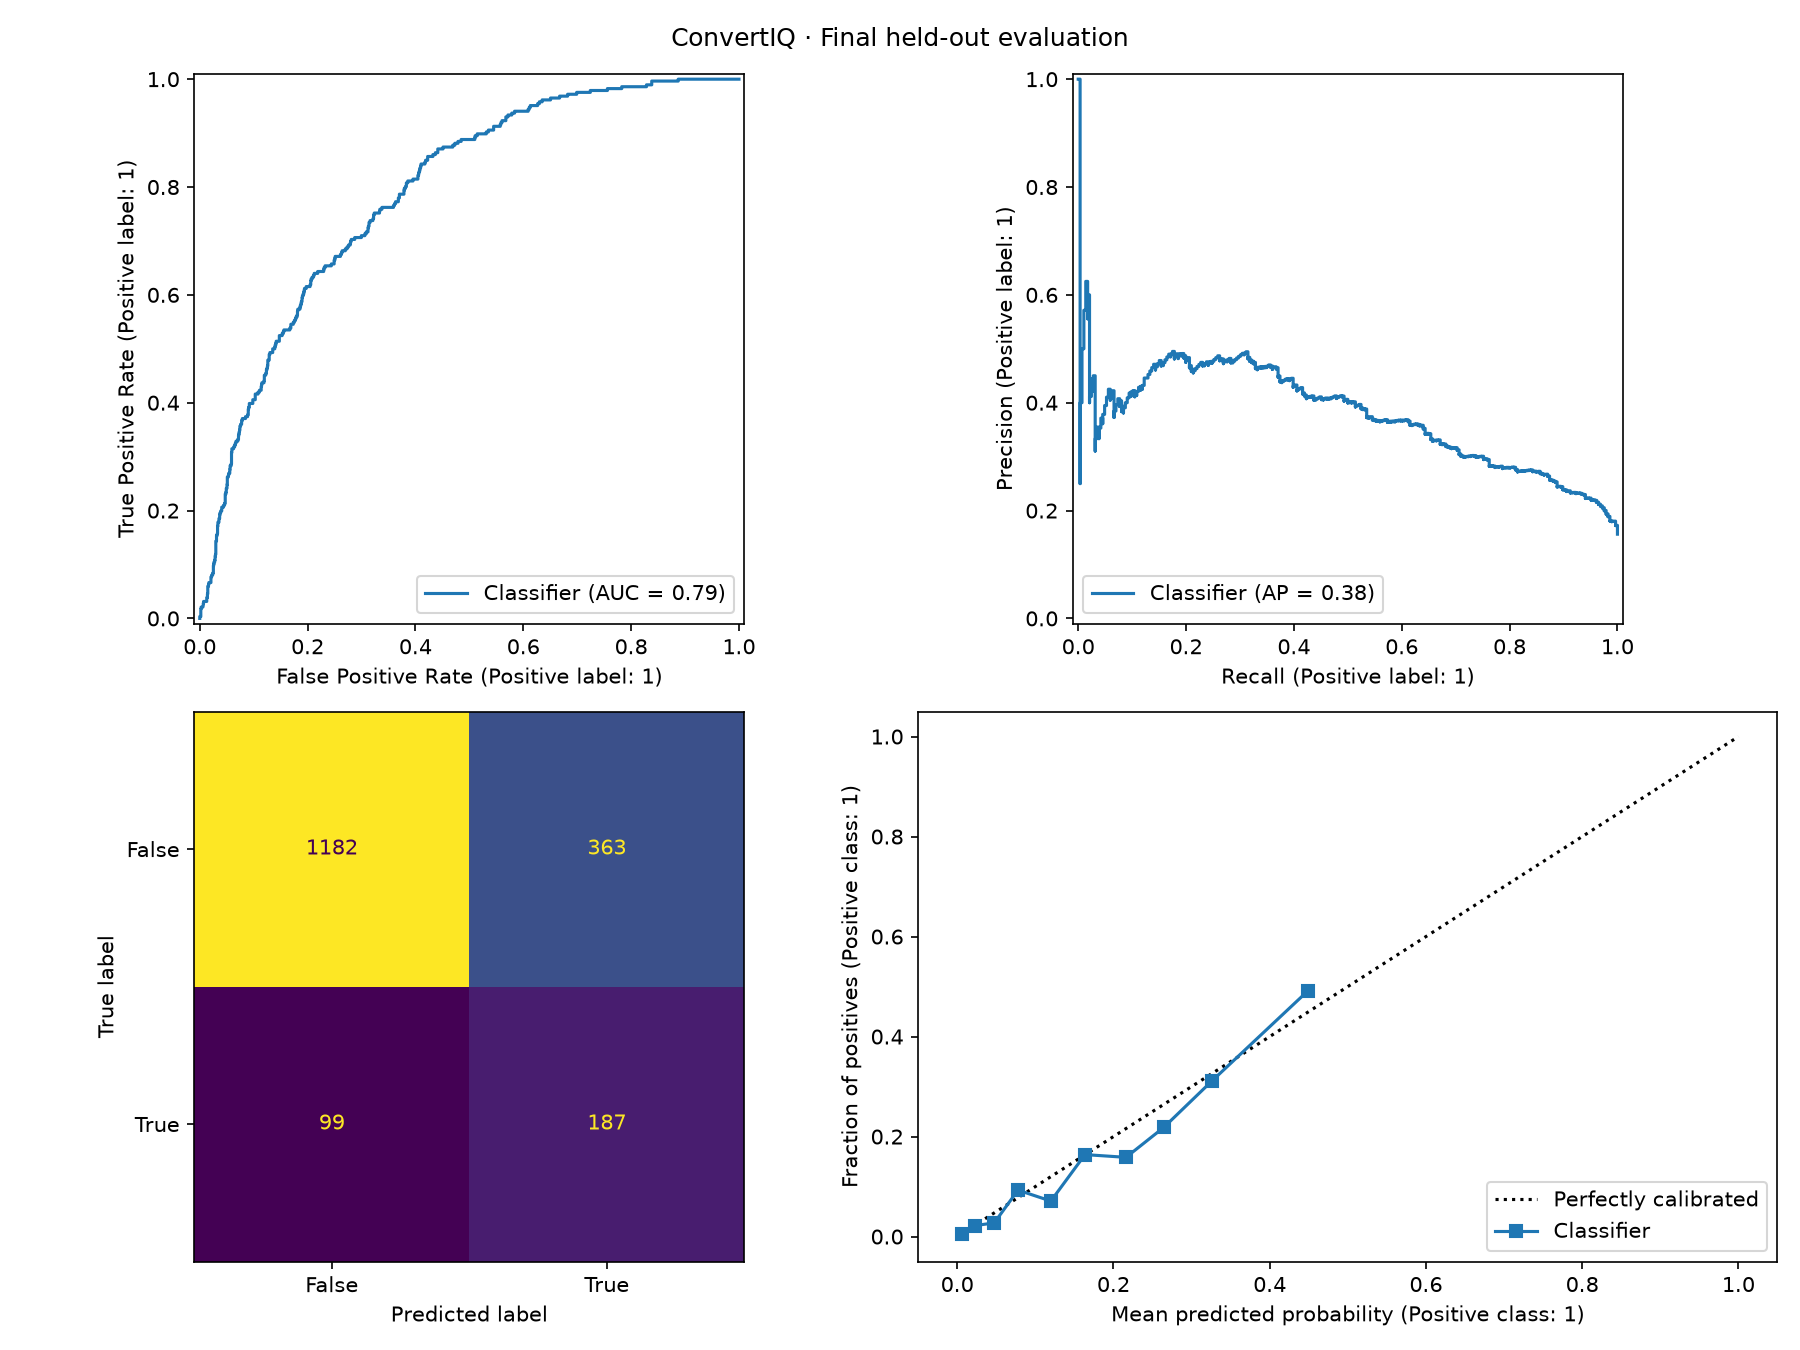

In [7]:
display(model.metadata["test_metrics"])
display(Image(filename=str(run / "evaluation.png")))

## Explainability and monitoring
Permutation importance measures a validation AP drop. SHAP approximates additive probability contributions against a training background; correlated inputs can produce unlikely combinations. Neither explanation establishes causality. Monitoring computes actual performance only when valid labels exist.

In [8]:
display(pd.read_csv(run / "permutation_importance.csv"))
display(pd.read_csv(run / "mutual_information.csv").head(20))
display(model.explain(model.background.iloc[:1]))

,feature,importance,std
0,ExitRates,0.058505,0.005223
1,ProductRelated_Duration,0.057062,0.038101
2,VisitorType,0.025400,0.001666
3,ProductRelated,0.022413,0.009637
4,Month,0.021039,0.009346
5,OperatingSystems,0.017002,0.002148
6,Administrative,0.013383,0.012042
7,TrafficType,0.012064,0.006512
8,Informational_Duration,0.009279,0.001488
9,Administrative_Duration,0.006895,0.009032


,feature,mutual_information
0,ExitRates,0.034873
1,ProductRelated_Duration,0.031068
2,BounceRates,0.023916
3,ProductRelated,0.020558
4,Administrative_Duration,0.015740
5,Administrative,0.012804
6,Month_Nov,0.012004
7,SpecialDay,0.006679
8,TrafficType_2,0.006501
9,VisitorType_New_Visitor,0.004634


/Users/ansh/Desktop/Project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'method': 'SHAP permutation (one permutation; approximate)',
 'units': 'probability',
 'base_value': 0.23948976394747093,
 'probability': 0.3075314221271496,
 'contributions': {'Administrative': np.float64(0.020873206134899944),
  'Informational': np.float64(-0.0003765076203398887),
  'ProductRelated': np.float64(0.014899205510352495),
  'Administrative_Duration': np.float64(-0.005230258718378122),
  'Informational_Duration': np.float64(0.0015716274182730056),
  'ProductRelated_Duration': np.float64(0.021344843930791488),
  'BounceRates': np.float64(0.0193097739962005),
  'ExitRates': np.float64(0.009678575051491736),
  'SpecialDay': np.float64(0.0014076169864665478),
  'Month': np.float64(-0.015532844912573632),
  'OperatingSystems': np.float64(0.006379845527093642),
  'Browser': np.float64(0.0011656505167215586),
  'Region': np.float64(0.002370366737068891),
  'TrafficType': np.float64(-0.0032245297016141317),
  'VisitorType': np.float64(-0.002896209344138853),
  'Weekend': np.float

## Business use and next experiment
Use propensity for prioritization hypotheses, subject to operational costs and capacity. A randomized, prospectively measured experiment is required to estimate incremental conversion or profit. Before early-session deployment, acquire event-time features and point-in-time labels, validate on later periods and monitor matured outcomes. Train-only feature-selection rankings are diagnostic; adding derived features is justified only by the validation ablation.